In [1]:
import os
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.anova import AnovaRM
from statsmodels.stats.multitest import multipletests

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 100)


In [2]:
# /Users/rashid/data/PhD/datacloud_data/repos/XAI/ShapBPT-SAM/shap_bpt_sam/examples/results/xai_results_E1_1_4/auc_results_all_images_500_220.csv
# /Users/rashid/data/PhD/datacloud_data/repos/XAI/ShapBPT-SAM/shap_bpt_sam/examples/results/xai_results_E2_1/auc_results_all_images_500_211.csv
# /Users/rashid/data/PhD/datacloud_data/repos/XAI/ShapBPT-SAM/shap_bpt_sam/examples/results/xai_results_E3_1/auc_results_all_images_500_190.csv

paths = {
    'E1_yolo': '/Users/rashid/data/PhD/datacloud_data/repos/XAI/ShapBPT-SAM/shap_bpt_sam/examples/results/xai_results_E1_1_4/auc_results_all_images_500_220.csv',
    'E2_resnet50': '/Users/rashid/data/PhD/datacloud_data/repos/XAI/ShapBPT-SAM/shap_bpt_sam/examples/results/xai_results_E2_1/auc_results_all_images_500_211.csv',
    'E3_vit_b16': '/Users/rashid/data/PhD/datacloud_data/repos/XAI/ShapBPT-SAM/shap_bpt_sam/examples/results/xai_results_E3_1/auc_results_all_images_500_190.csv',
}

dfs = []
for experiment, path in paths.items():
    df = pd.read_csv(path)
    df['experiment'] = experiment
    dfs.append(df)

df_e1, df_e2, df_e3 = dfs
all_df = pd.concat(dfs, ignore_index=True)

display(all_df.groupby(['experiment', 'method'])['image_no'].nunique().unstack(fill_value=0))


method,BPT,boosted,boosted_filled,compact_selection,filled,greedy_selection,sam,sam_kernelshap
experiment,,,,,,,,
E1_yolo,220,220,220,220,220,220,220,220
E2_resnet50,211,211,211,211,211,211,211,211
E3_vit_b16,190,190,190,190,190,190,190,190


In [3]:
# df_e1


In [4]:
from statsmodels.stats.anova import AnovaRM

## Repeated-Measures ANOVA by Method

Each image is measured under every XAI method, so the method comparison is paired/repeated-measures. The cells below run one ANOVA per experiment and metric after keeping only images with complete method coverage for that metric.


In [5]:
METRICS = [
    'auc_ins', 'auc_del',
    # 'drop_at_10', 'drop_at_20', 'drop_at_30',
    # 'insert_at_10', 'insert_at_20', 'insert_at_30',
    # 'sufficiency_at_10', 'sufficiency_at_20',
    # 'sufficiency_gap_at_10', 'sufficiency_gap_at_20',
    # 'comprehensiveness_at_10', 'comprehensiveness_at_20',
    # 'sensitivity_n_corr', 
    'stability_top10_jaccard',
]
METRICS = [m for m in METRICS if m in all_df.columns]
METHODS = list(all_df['method'].dropna().unique())

def partial_eta_squared_from_f(f_value, df_num, df_den):
    if not np.isfinite(f_value):
        return np.nan
    return (f_value * df_num) / (f_value * df_num + df_den)

def complete_cases_for_metric(df, metric, methods=None):
    methods = methods or sorted(df['method'].dropna().unique())
    sub = df[['image_no', 'method', metric]].dropna().copy()
    sub = sub[sub['method'].isin(methods)]
    pivot = sub.pivot_table(index='image_no', columns='method', values=metric, aggfunc='mean')
    present_methods = [m for m in methods if m in pivot.columns]
    pivot = pivot[present_methods].dropna()
    long = pivot.reset_index().melt(id_vars='image_no', var_name='method', value_name=metric)
    return pivot, long

def run_repeated_measures_anova(df, experiment, metrics=METRICS):
    rows = []
    exp_df = df[df['experiment'] == experiment].copy()
    methods = sorted(exp_df['method'].dropna().unique())
    for metric in metrics:
        pivot, long = complete_cases_for_metric(exp_df, metric, methods=methods)
        if pivot.shape[0] < 2 or pivot.shape[1] < 2:
            rows.append({'experiment': experiment, 'metric': metric, 'n_images': pivot.shape[0], 'n_methods': pivot.shape[1], 'F': np.nan, 'p': np.nan, 'partial_eta2': np.nan, 'note': 'not enough complete data'})
            continue
        try:
            result = AnovaRM(long, depvar=metric, subject='image_no', within=['method']).fit()
            table = result.anova_table.reset_index().rename(columns={'index': 'effect'})
            row = table.iloc[0]
            f_value = float(row['F Value'])
            df_num = float(row['Num DF'])
            df_den = float(row['Den DF'])
            rows.append({
                'experiment': experiment,
                'metric': metric,
                'n_images': int(pivot.shape[0]),
                'n_methods': int(pivot.shape[1]),
                'F': f_value,
                'df_num': df_num,
                'df_den': df_den,
                'p': float(row['Pr > F']),
                'partial_eta2': partial_eta_squared_from_f(f_value, df_num, df_den),
                'note': '',
            })
        except Exception as exc:
            groups = [pivot[col].to_numpy() for col in pivot.columns]
            f_value, p_value = stats.f_oneway(*groups)
            rows.append({'experiment': experiment, 'metric': metric, 'n_images': int(pivot.shape[0]), 'n_methods': int(pivot.shape[1]), 'F': f_value, 'p': p_value, 'partial_eta2': np.nan, 'note': f'fallback one-way ANOVA: {exc}'})
    return pd.DataFrame(rows)

anova_df = pd.concat([run_repeated_measures_anova(all_df, exp) for exp in paths], ignore_index=True)
anova_df['significant_0.05'] = anova_df['p'] < 0.05
anova_df.sort_values(['experiment', 'p']).reset_index(drop=True)


,experiment,metric,n_images,n_methods,F,df_num,df_den,p,partial_eta2,note,significant_0.05
0,E1_yolo,auc_del,220,8,71.908270,7.0,1533.0,4.575486e-90,0.247185,,True
1,E1_yolo,stability_top10_jaccard,220,8,71.298196,7.0,1533.0,2.250837e-89,0.245603,,True
2,E1_yolo,auc_ins,220,8,57.136561,7.0,1533.0,6.546653e-73,0.206914,,True
3,E2_resnet50,stability_top10_jaccard,211,8,106.894328,7.0,1470.0,1.345157e-126,0.337319,,True
4,E2_resnet50,auc_ins,211,8,103.536337,7.0,1470.0,3.208632e-123,0.330221,,True
5,E2_resnet50,auc_del,211,8,59.438642,7.0,1470.0,2.845335e-75,0.220602,,True
6,E3_vit_b16,stability_top10_jaccard,190,8,108.461456,7.0,1323.0,1.396887e-125,0.364624,,True
7,E3_vit_b16,auc_ins,190,8,99.646346,7.0,1323.0,5.349310e-117,0.345219,,True
8,E3_vit_b16,auc_del,190,8,62.946853,7.0,1323.0,2.788215e-78,0.249842,,True


## Post-Hoc Paired Method Tests

After ANOVA says that methods differ, this cell shows which pairs differ using paired t-tests across the same images with Holm correction. Change `POSTHOC_EXPERIMENT` and `POSTHOC_METRIC` to inspect another result.


In [7]:
# df_e1


## Use AnovaRM

This block uses `statsmodels.stats.anova.AnovaRM` directly. For each experiment and metric, it first keeps only paired complete cases: the same image must have a value for every method included in that experiment.


In [8]:
ANOVARM_METRICS = ['auc_ins', 'auc_del']
ANOVARM_EXPERIMENTS = list(paths.keys())

def run_anovarm_by_experiment(df, experiments=ANOVARM_EXPERIMENTS, metrics=ANOVARM_METRICS):
    rows = []
    fitted_models = {}

    for experiment in experiments:
        exp_df = df[df['experiment'] == experiment].copy()
        methods = sorted(exp_df['method'].dropna().unique())

        for metric in metrics:
            pivot, long_df = complete_cases_for_metric(exp_df, metric, methods=methods)
            if pivot.shape[0] < 2 or pivot.shape[1] < 2:
                rows.append({
                    'experiment': experiment,
                    'metric': metric,
                    'n_images': int(pivot.shape[0]),
                    'n_methods': int(pivot.shape[1]),
                    'methods': ', '.join(map(str, pivot.columns)),
                    'F': np.nan,
                    'df_num': np.nan,
                    'df_den': np.nan,
                    'p_value': np.nan,
                    'partial_eta2': np.nan,
                    'note': 'not enough complete paired data',
                })
                continue

            fit = AnovaRM(long_df, depvar=metric, subject='image_no', within=['method']).fit()
            fitted_models[(experiment, metric)] = fit
            table = fit.anova_table.reset_index().rename(columns={'index': 'effect'})
            method_row = table.iloc[0]

            f_value = float(method_row['F Value'])
            df_num = float(method_row['Num DF'])
            df_den = float(method_row['Den DF'])
            p_value = float(method_row['Pr > F'])

            rows.append({
                'experiment': experiment,
                'metric': metric,
                'n_images': int(pivot.shape[0]),
                'n_methods': int(pivot.shape[1]),
                'methods': ', '.join(map(str, pivot.columns)),
                'F': f_value,
                'df_num': df_num,
                'df_den': df_den,
                'p_value': p_value,
                'partial_eta2': partial_eta_squared_from_f(f_value, df_num, df_den),
                'note': '',
            })

    return pd.DataFrame(rows), fitted_models

anovarm_results_df, anovarm_fits = run_anovarm_by_experiment(all_df)
anovarm_results_df['significant_0.05'] = anovarm_results_df['p_value'] < 0.05
anovarm_results_df.sort_values(['experiment', 'metric']).reset_index(drop=True)


,experiment,metric,n_images,n_methods,methods,F,df_num,df_den,p_value,partial_eta2,note,significant_0.05
0,E1_yolo,auc_del,220,8,"BPT, boosted, boosted_filled, compact_selectio...",71.908270,7.0,1533.0,4.575486e-90,0.247185,,True
1,E1_yolo,auc_ins,220,8,"BPT, boosted, boosted_filled, compact_selectio...",57.136561,7.0,1533.0,6.546653e-73,0.206914,,True
2,E2_resnet50,auc_del,211,8,"BPT, boosted, boosted_filled, compact_selectio...",59.438642,7.0,1470.0,2.845335e-75,0.220602,,True
3,E2_resnet50,auc_ins,211,8,"BPT, boosted, boosted_filled, compact_selectio...",103.536337,7.0,1470.0,3.208632e-123,0.330221,,True
4,E3_vit_b16,auc_del,190,8,"BPT, boosted, boosted_filled, compact_selectio...",62.946853,7.0,1323.0,2.788215e-78,0.249842,,True
5,E3_vit_b16,auc_ins,190,8,"BPT, boosted, boosted_filled, compact_selectio...",99.646346,7.0,1323.0,5.349310e-117,0.345219,,True


In [9]:
# Mean ranking per experiment/metric, useful for interpreting significant ANOVA results.
rank_rows = []
for experiment in ANOVARM_EXPERIMENTS:
    exp_df = all_df[all_df['experiment'] == experiment].copy()
    methods = sorted(exp_df['method'].dropna().unique())
    for metric in ANOVARM_METRICS:
        pivot, _ = complete_cases_for_metric(exp_df, metric, methods=methods)
        if pivot.empty:
            continue
        means = pivot.mean().sort_values(ascending=(metric == 'auc_del'))
        for rank, (method, mean_value) in enumerate(means.items(), start=1):
            rank_rows.append({
                'experiment': experiment,
                'metric': metric,
                'rank': rank,
                'method': method,
                'mean': float(mean_value),
                'n_images': int(pivot.shape[0]),
                'better_direction': 'higher' if metric == 'auc_ins' else 'lower',
            })

method_mean_rank_df = pd.DataFrame(rank_rows)
method_mean_rank_df.sort_values(['experiment', 'metric', 'rank']).reset_index(drop=True)


,experiment,metric,rank,method,mean,n_images,better_direction
0,E1_yolo,auc_del,1,compact_selection,0.091131,220,lower
1,E1_yolo,auc_del,2,greedy_selection,0.091131,220,lower
2,E1_yolo,auc_del,3,filled,0.091973,220,lower
3,E1_yolo,auc_del,4,boosted_filled,0.093492,220,lower
4,E1_yolo,auc_del,5,boosted,0.093997,220,lower
5,E1_yolo,auc_del,6,sam,0.096961,220,lower
6,E1_yolo,auc_del,7,BPT,0.101903,220,lower
7,E1_yolo,auc_del,8,sam_kernelshap,0.212366,220,lower
8,E1_yolo,auc_ins,1,boosted,0.800742,220,higher
9,E1_yolo,auc_ins,2,boosted_filled,0.796987,220,higher


In [10]:
POSTHOC_EXPERIMENT = 'E1_yolo'
POSTHOC_METRIC = 'auc_ins'

def paired_posthoc_tests(df, experiment, metric):
    exp_df = df[df['experiment'] == experiment].copy()
    methods = sorted(exp_df['method'].dropna().unique())
    pivot, _ = complete_cases_for_metric(exp_df, metric, methods=methods)
    rows = []
    for method_a, method_b in combinations(pivot.columns, 2):
        a = pivot[method_a].to_numpy()
        b = pivot[method_b].to_numpy()
        diff = a - b
        stat, p_value = stats.ttest_rel(a, b, nan_policy='omit')
        
        rows.append({
            'experiment': experiment,
            'metric': metric,
            'method_a': method_a,
            'method_b': method_b,
            'p_raw': float(p_value),
            'n_images': int(len(diff)),
            'mean_a': float(np.nanmean(a)),
            'mean_b': float(np.nanmean(b)),
            'mean_diff_a_minus_b': float(np.nanmean(diff)),
            't': float(stat),
            # 'p_raw': float(p_value),
        })
    out = pd.DataFrame(rows)
    if not out.empty:
        out['p_holm'] = multipletests(out['p_raw'], method='holm')[1]
        out['significant_0.05'] = out['p_holm'] < 0.05
    return out.sort_values('p_holm').reset_index(drop=True)

posthoc_df = paired_posthoc_tests(all_df, POSTHOC_EXPERIMENT, POSTHOC_METRIC)
posthoc_df


,experiment,metric,method_a,method_b,p_raw,n_images,mean_a,mean_b,mean_diff_a_minus_b,t,p_holm,significant_0.05
0,E1_yolo,auc_ins,boosted,sam_kernelshap,4.045200e-23,220,0.800742,0.648391,0.152351,11.137373,1.132656e-21,True
1,E1_yolo,auc_ins,filled,sam_kernelshap,1.145802e-21,220,0.793980,0.648391,0.145588,10.668029,3.093664e-20,True
2,E1_yolo,auc_ins,boosted_filled,sam_kernelshap,1.462180e-21,220,0.796987,0.648391,0.148595,10.633575,3.801667e-20,True
3,E1_yolo,auc_ins,compact_selection,sam_kernelshap,3.210906e-21,220,0.792257,0.648391,0.143866,10.522184,8.027264e-20,True
4,E1_yolo,auc_ins,greedy_selection,sam_kernelshap,3.210906e-21,220,0.792257,0.648391,0.143866,10.522184,8.027264e-20,True
5,E1_yolo,auc_ins,sam,sam_kernelshap,8.281393e-20,220,0.785276,0.648391,0.136885,10.057859,1.904720e-18,True
6,E1_yolo,auc_ins,BPT,sam_kernelshap,2.608718e-19,220,0.786154,0.648391,0.137762,9.892182,5.739179e-18,True
7,E1_yolo,auc_ins,boosted,sam,4.496561e-02,220,0.800742,0.785276,0.015466,2.016530,9.442779e-01,False
8,E1_yolo,auc_ins,greedy_selection,sam,3.651831e-01,220,0.792257,0.785276,0.006982,0.907418,1.000000e+00,False
9,E1_yolo,auc_ins,filled,sam,2.379565e-01,220,0.793980,0.785276,0.008704,1.183342,1.000000e+00,False


## Mean Metric Plot

This plot gives a quick visual companion to the ANOVA table. For `auc_ins`, higher is better. For `auc_del`, lower is better.


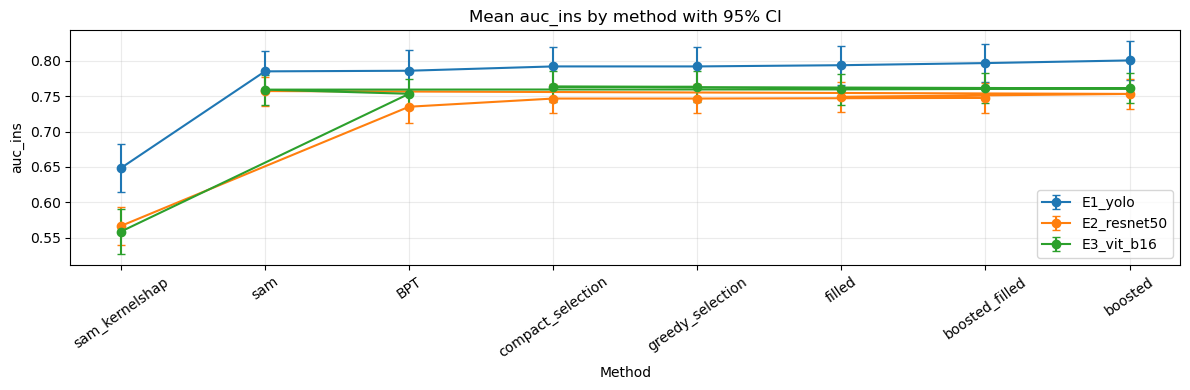

In [11]:
PLOT_METRIC = 'auc_ins'

summary = (
    all_df.dropna(subset=[PLOT_METRIC])
    .groupby(['experiment', 'method'])[PLOT_METRIC]
    .agg(['mean', 'std', 'count'])
    .reset_index()
)
summary['sem'] = summary['std'] / np.sqrt(summary['count'])

fig, ax = plt.subplots(figsize=(12, 4))
for experiment, sub in summary.groupby('experiment'):
    sub = sub.sort_values('mean', ascending=PLOT_METRIC not in {'auc_del'})
    ax.errorbar(sub['method'], sub['mean'], yerr=1.96 * sub['sem'], marker='o', capsize=3, label=experiment)

ax.set_title(f'Mean {PLOT_METRIC} by method with 95% CI')
ax.set_xlabel('Method')
ax.set_ylabel(PLOT_METRIC)
ax.tick_params(axis='x', rotation=35)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()
